# Masked Autoencoders for Unseen-Activity Detection on UCI-HAR

A self-supervised time-series experiment on real smartphone sensor recordings.

*How does the capacity of a compact masked autoencoder affect reconstruction quality and detection of an activity excluded from training?*

We train three lightweight models on five human activities and evaluate reconstruction-error scores on the held-out activity.


## 1. Import and Reproducibility

Import dependencies, set the random seed, and select CPU or GPU.

In [1]:
import io
import zipfile
import urllib.request
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import roc_auc_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

In [2]:
SEED = 42
WINDOW, CHANNELS = 128, 9
PATCH, MASK_RATIO = 8, 0.50
HIDDENS = (4, 16, 64)
EPOCHS, BATCH_SIZE, LEARNING_RATE = 15, 128, 1e-3
EVAL_REPEATS, EVAL_SEED = 8, 2026
SEEDS = (42, 43, 44)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

ACTIVITY_NAMES = {
    1: "WALKING", 2: "WALKING_UPSTAIRS", 3: "WALKING_DOWNSTAIRS",
    4: "SITTING", 5: "STANDING", 6: "LAYING",
}
ACTIVITIES = tuple(ACTIVITY_NAMES)
BASE_SEEN = (1, 2, 3, 4, 5)
BASE_UNSEEN = 6

np.random.seed(SEED)
torch.manual_seed(SEED)
print("Device:", DEVICE)

Device: cpu


## 2. Load the Original UCI-HAR Sensor Windows

UCI-HAR contains recordings from 30 volunteers performing six activities, captured by smartphone accelerometer and gyroscope sensors at 50 Hz. The official split has 7,352 training and 2,947 test windows, with disjoint participants.

Each window spans 128 samples and has 9 channels, body acceleration, body gyroscope, and total acceleration along the x, y, and z axes.

In [3]:
DATA_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
DATA_FILE = Path("uci_har_original.zip")
if not DATA_FILE.exists():
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

In [4]:
# Read a numeric text file from the UCI-HAR ZIP archive
def read_archive_array(archive, path):
    return np.loadtxt(io.BytesIO(archive.read(f"UCI HAR Dataset/{path}")))

In [5]:
# Load sensor windows, activity labels, and subject IDs
def load_split(archive, split):
    names = [f"{sensor}_{axis}"
             for sensor in ("body_acc", "body_gyro", "total_acc")
             for axis in "xyz"]
    signals = [read_archive_array(archive, f"{split}/Inertial Signals/{name}_{split}.txt")
               for name in names]
    X = np.stack(signals, axis=-1).astype(np.float32)
    y = read_archive_array(archive, f"{split}/y_{split}.txt").astype(np.int64)
    subjects = read_archive_array(archive, f"{split}/subject_{split}.txt").astype(np.int64)
    return X, y, subjects

In [6]:
# Call the loading functions
with zipfile.ZipFile(DATA_FILE) as outer:
    inner_files = [name for name in outer.namelist() if name.lower().endswith(".zip")]
    if inner_files:
        with zipfile.ZipFile(io.BytesIO(outer.read(inner_files[0]))) as archive:
            X_train_all, y_train_all, subjects_train = load_split(archive, "train")
            X_test_all, y_test_all, subjects_test = load_split(archive, "test")
    else:
        X_train_all, y_train_all, subjects_train = load_split(outer, "train")
        X_test_all, y_test_all, subjects_test = load_split(outer, "test")

assert X_train_all.shape[1:] == X_test_all.shape[1:] == (WINDOW, CHANNELS)
assert set(subjects_train).isdisjoint(subjects_test)
assert set(np.unique(y_train_all)) == set(np.unique(y_test_all)) == set(ACTIVITIES)
print("Train:", X_train_all.shape, "| Test:", X_test_all.shape)

Train: (7352, 128, 9) | Test: (2947, 128, 9)


## 3. Define the Unseen-Class OOD Protocol

The six activity labels are: `1 WALKING`, `2 WALKING_UPSTAIRS`, `3 WALKING_DOWNSTAIRS`, `4 SITTING`, `5 STANDING`, and `6 LAYING`.

Experimental Split:

* Self-supervised training: all official training windows except LAYING.
* Known test set: the five retained activities from official test subjects.
* OOD test set: LAYING windows from official test subjects.

This uses labels to design the benchmark, not to train the encoder.

In [7]:
# Select seen training windows, normalize using only training statistics, and prepare held-out test windows
def prepare_data(seen_ids):
    seen_ids = tuple(sorted(seen_ids))
    if not seen_ids or not set(seen_ids).issubset(ACTIVITIES):
        raise ValueError("seen_ids must contain valid UCI-HAR activity IDs")

    raw_train = X_train_all[np.isin(y_train_all, seen_ids)]
    mean = raw_train.mean(axis=(0, 1), keepdims=True)
    std = raw_train.std(axis=(0, 1), keepdims=True).clip(min=1e-5)

    return {
        "train": ((raw_train - mean) / std).astype(np.float32),
        "seen_test": ((X_test_all[np.isin(y_test_all, seen_ids)] - mean) / std).astype(np.float32),
        "unseen_test": {
            activity: ((X_test_all[y_test_all == activity] - mean) / std).astype(np.float32)
            for activity in ACTIVITIES if activity not in seen_ids
        },
    }

In [8]:
# Create the baseline split
baseline_data = prepare_data(BASE_SEEN)
print("Seen Train:", len(baseline_data["train"]))
print("Seen Test:", len(baseline_data["seen_test"]))
print("Unseen Test:", len(baseline_data["unseen_test"][BASE_UNSEEN]))

Seen Train: 5945
Seen Test: 2410
Unseen Test: 537


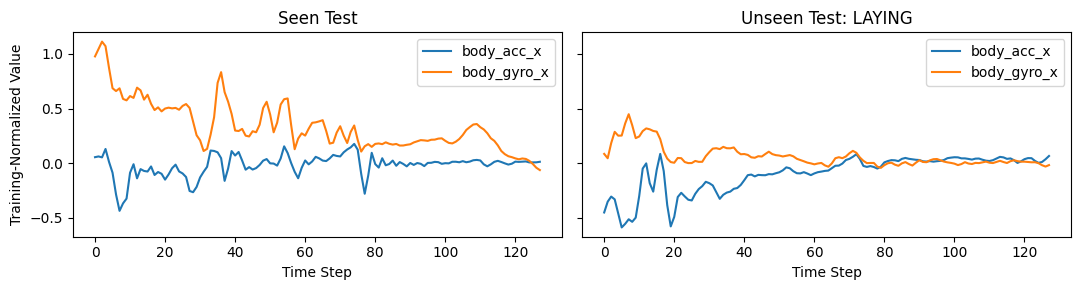

In [9]:
# Plot two normalized windows
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
examples = (baseline_data["seen_test"][0], baseline_data["unseen_test"][BASE_UNSEEN][0])
for ax, x, title in zip(axes, examples, ("Seen Test", "Unseen Test: LAYING")):
    ax.plot(x[:, 0], label="body_acc_x")
    ax.plot(x[:, 3], label="body_gyro_x")
    ax.set(xlabel="Time Step", title=title)
    ax.legend()
axes[0].set_ylabel("Training-Normalized Value")
plt.tight_layout()
plt.show()

## 5. Masked Reconstruction Model

We divide each 128-step window into 16 non-overlapping patches of 8 steps and randomly hide 50% of the patches. All nine channels in a selected patch are hidden together.

The network receives the masked signal and an explicit mask indicator, compresses them with a small fully connected encoder, and predicts the full window using a linear decoder. Loss is computed only at masked positions.

We vary only the hidden dimension to study the effect of model capacity.

A Boolean mask marks the hidden time steps. The same time steps are masked across all sensor channels.

In [10]:
# Sample masks that hide the same patches across all nine channels
def make_masks(batch_size, patch=PATCH, mask_ratio=MASK_RATIO, generator=None):
    if WINDOW % patch:
        raise ValueError("Patch size must divide the window length")
    n_patches = WINDOW // patch
    n_masked = int(n_patches * mask_ratio)
    if not 0 < n_masked < n_patches:
        raise ValueError("Keep at least one visible and one hidden patch")
    ranks = torch.rand((batch_size, n_patches), generator=generator).argsort(dim=1)
    return (ranks < n_masked).repeat_interleave(patch, dim=1).unsqueeze(-1)

The encoder maps the flattened masked window and mask indicator into a low-dimensional representation, the decoder maps that representation back to 128 × 9 values. The reported total parameter count includes both encoder and decoder.

In [11]:
# Encode a masked sensor window and decode it back to the original shape
class MaskedAutoencoder(nn.Module):
    def __init__(self, hidden):
        super().__init__()
        size = WINDOW * CHANNELS
        self.encoder = nn.Sequential(
            nn.Linear(size + WINDOW, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
        )
        self.decoder = nn.Linear(hidden, size)

    def forward(self, x, mask):
        masked_x = x.masked_fill(mask, 0.0)
        encoded = self.encoder(torch.cat(
            (masked_x.flatten(1), mask.squeeze(-1).float()), dim=1
        ))
        return self.decoder(encoded).reshape_as(x)

Visible values do not contribute to the training objective. This forces the model to infer missing measurements from the observed temporal context.

In [12]:
# Compute reconstruction MSE using only the hidden measurements
def masked_mse(prediction, target, mask):
    weights = mask.expand_as(target)
    return (((prediction - target) ** 2) * weights).sum() / weights.sum()

Train independently on unlabeled known-activity windows using Adam and the masked MSE objective. We keep the data, masking ratio, optimizer, and number of epochs fixed so capacity is the main variable.

Training loss measures reconstruction fit on masked training windows, it does not directly measure OOD detection quality.

For each hidden dimension, initialize a new model, sample masks per batch, and optimize masked reconstruction error.


In [13]:
# Run one training epoch and return its average masked reconstruction loss
def train_one_epoch(model, loader, optimizer, mask_rng, patch, mask_ratio):
    model.train()
    total = 0.0
    for (batch,) in loader:
        batch = batch.to(DEVICE)
        mask = make_masks(len(batch), patch, mask_ratio, mask_rng).to(DEVICE)
        optimizer.zero_grad()
        loss = masked_mse(model(batch, mask), batch, mask)
        loss.backward()
        optimizer.step()
        total += float(loss.item()) * len(batch)
    return total / len(loader.dataset)

In [14]:
# Train one autoencoder using shared hyperparameters and a reproducible seed
def train_model(train_windows, hidden, seed=SEED, patch=PATCH, mask_ratio=MASK_RATIO):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    model = MaskedAutoencoder(hidden).to(DEVICE)
    loader = DataLoader(
        TensorDataset(torch.from_numpy(train_windows)),
        batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(seed + 1000),
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    mask_rng = torch.Generator().manual_seed(seed + 2000)
    history = [train_one_epoch(model, loader, optimizer, mask_rng, patch, mask_ratio)
               for _ in range(EPOCHS)]
    return model, history

After training, freeze each model and score test windows using masked reconstruction error. To reduce sensitivity to any single random mask, average the per-window score over eight masking repetitions. A larger score means the masked values were harder to reconstruct.


In [15]:
# Score each window by masked reconstruction MSE averaged over fixed random masks
def reconstruction_scores(model, windows, patch=PATCH, mask_ratio=MASK_RATIO):
    model.eval()
    mask_rng = torch.Generator().manual_seed(EVAL_SEED)
    batches = []
    with torch.no_grad():
        for start in range(0, len(windows), BATCH_SIZE):
            batch = torch.from_numpy(windows[start:start + BATCH_SIZE]).to(DEVICE)
            total = torch.zeros(len(batch), device=DEVICE)
            for _ in range(EVAL_REPEATS):
                mask = make_masks(len(batch), patch, mask_ratio, mask_rng).to(DEVICE)
                weights = mask.expand_as(batch)
                residual = (model(batch, mask) - batch) ** 2
                total += (residual * weights).sum((1, 2)) / weights.sum((1, 2))
            batches.append((total / EVAL_REPEATS).cpu().numpy())
    return np.concatenate(batches)

Assign known windows label `0` and held-out LAYING windows label `1`.

In [16]:
# Calculate AUROC from masked reconstruction MSE for seen and unseen windows
def compute_auroc(seen_scores, unseen_scores):
    labels = np.r_[np.zeros(len(seen_scores)), np.ones(len(unseen_scores))]
    scores = np.r_[seen_scores, unseen_scores]
    return roc_auc_score(labels, scores)

Train hidden dimensions 4, 16, and 64, then visualize how masked reconstruction loss changes over epochs.

In [17]:
# Train each baseline capacity; keep the models and loss histories for later reuse.
models, histories = {}, {}
for hidden in HIDDENS:
    model, history = train_model(baseline_data["train"], hidden)
    models[hidden], histories[hidden] = model, history
    print(f"Hidden={hidden:2d} | Params={sum(p.numel() for p in model.parameters()):,}"
          f" | Train Masked MSE={history[-1]:.4f}")

Hidden= 4 | Params=10,904 | Train Masked MSE=0.8541
Hidden=16 | Params=40,352 | Train Masked MSE=0.6523
Hidden=64 | Params=161,024 | Train Masked MSE=0.5301


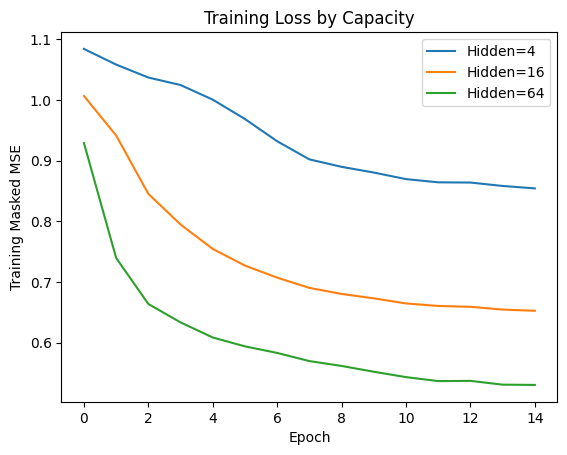

In [18]:
# Plot baseline training loss without mixing plotting with model training.
for hidden in HIDDENS:
    plt.plot(histories[hidden], label=f"Hidden={hidden}")
plt.xlabel("Epoch")
plt.ylabel("Training Masked MSE")
plt.title("Training Loss by Capacity")
plt.legend()
plt.show()

In [19]:
# Report mean reconstruction MSE and AUROC for the baseline capacities
baseline_scores, baseline_rows = {}, []
for hidden, model in models.items():
    seen = reconstruction_scores(model, baseline_data["seen_test"])
    unseen = reconstruction_scores(model, baseline_data["unseen_test"][BASE_UNSEEN])
    baseline_scores[hidden] = (seen, unseen)
    baseline_rows.append({
        "hidden": hidden,
        "seen_test_MSE": float(seen.mean()),
        "unseen_test_MSE": float(unseen.mean()),
        "AUROC": compute_auroc(seen, unseen),
    })
baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results.round(4))

,hidden,seen_test_MSE,unseen_test_MSE,AUROC
0,4,0.7843,2.0943,0.8843
1,16,0.6335,1.3253,0.7982
2,64,0.5383,0.7104,0.6255


The histograms show whether known and held-out activity scores overlap.

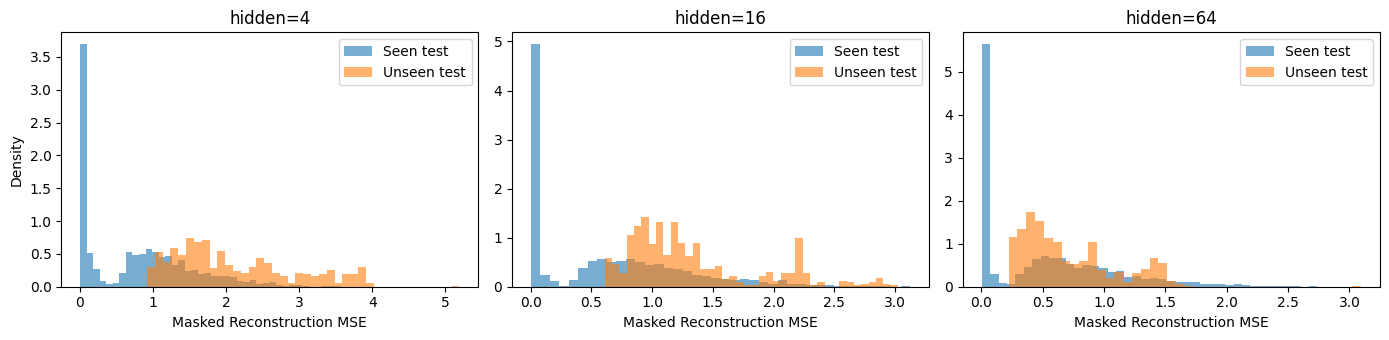

In [20]:
# Visualize baseline reconstruction-score separation for each capacity
fig, axes = plt.subplots(1, len(HIDDENS), figsize=(14, 3.5))
for ax, hidden in zip(np.ravel(axes), HIDDENS):
    seen, unseen = baseline_scores[hidden]
    ax.hist(seen, bins=40, alpha=0.6, density=True, label="Seen test")
    ax.hist(unseen, bins=40, alpha=0.6, density=True, label="Unseen test")
    ax.set(title=f"hidden={hidden}", xlabel="Masked Reconstruction MSE")
    ax.legend()
np.ravel(axes)[0].set_ylabel("Density")
plt.tight_layout()
plt.show()

## 6. Ablation Study

Every experiment retrains a fresh masked autoencoder, varying just one of the following aspects at a time, which activity is held out, patch size, or masking ratio.

In [21]:
# Test different patch sizes and mask ratios
PATCH_SIZES = (4, 8, 16, 32)
MASK_RATIOS = (0.25, 0.50, 0.75)
assert all(WINDOW % p == 0 for p in PATCH_SIZES)

In [22]:
# Reuse the baseline model for the same configuration
def fit_configuration(data, seen_ids, hidden, seed, patch=PATCH, mask_ratio=MASK_RATIO):
    is_baseline = (tuple(seen_ids) == BASE_SEEN and seed == SEED
                   and patch == PATCH and mask_ratio == MASK_RATIO)
    if is_baseline:
        return models[hidden], histories[hidden]
    return train_model(data["train"], hidden, seed, patch, mask_ratio)

In [23]:
# Record seen/unseen mean reconstruction MSE and AUROC for one ablation run
def result_row(unseen_id, hidden, seed, patch, mask_ratio, seen_scores, unseen_scores):
    return {
        "unseen_id": unseen_id,
        "unseen_activity": ACTIVITY_NAMES[unseen_id],
        "hidden": hidden,
        "seed": seed,
        "patch_size": patch,
        "mask_ratio": mask_ratio,
        "seen_MSE": float(seen_scores.mean()),
        "unseen_MSE": float(unseen_scores.mean()),
        "AUROC": compute_auroc(seen_scores, unseen_scores),
    }

In [24]:
# Average MSE and AUROC across seeds for each ablation setting
def summarize_results(results, groups):
    return results.groupby(groups, as_index=False).agg(
        seen_MSE=("seen_MSE", "mean"),
        unseen_MSE=("unseen_MSE", "mean"),
        AUROC_mean=("AUROC", "mean"),
        AUROC_std=("AUROC", "std"),
    )

In [25]:
# Plot AUROC across ablation settings, showing variability between seeds
def plot_comparison(results, x, title, x_label, activity_ticks=False):
    fig, ax = plt.subplots(figsize=(8, 4))
    for hidden in HIDDENS:
        part = results[results["hidden"] == hidden]
        avg = part.groupby(x)["AUROC"].agg(["mean", "std"]).reset_index()
        ax.errorbar(avg[x], avg["mean"], yerr=avg["std"].fillna(0),
                    marker="o", capsize=3, label=f"hidden={hidden}")
    ax.set(title=title, xlabel=x_label, ylabel="AUROC", ylim=(-0.02, 1.02))
    ax.grid(alpha=0.25)
    ax.legend()
    if activity_ticks:
        ax.set_xticks(ACTIVITIES)
        ax.set_xticklabels([ACTIVITY_NAMES[a] for a in ACTIVITIES],
                           rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

### Which activity is unseen?

Exclude each activity in turn, train on the remaining five.

In [26]:
# Specify which activity is held out
scenarios_A = [tuple(a for a in ACTIVITIES if a != unseen) for unseen in ACTIVITIES]

In [27]:
# Fit, score, and record each held-out activity condition
rows_A = []
for seen_ids in scenarios_A:
    unseen_id = next(a for a in ACTIVITIES if a not in seen_ids)
    data = prepare_data(seen_ids)
    for hidden, seed in product(HIDDENS, SEEDS):
        model, history = fit_configuration(data, seen_ids, hidden, seed)
        seen_scores = reconstruction_scores(model, data["seen_test"])
        unseen_scores = reconstruction_scores(model, data["unseen_test"][unseen_id])
        rows_A.append(result_row(unseen_id, hidden, seed, PATCH, MASK_RATIO,
                                 seen_scores, unseen_scores))
    print(f"unseen: {ACTIVITY_NAMES[unseen_id]} Completed")
results_A = pd.DataFrame(rows_A)

unseen: WALKING Completed
unseen: WALKING_UPSTAIRS Completed
unseen: WALKING_DOWNSTAIRS Completed
unseen: SITTING Completed
unseen: STANDING Completed
unseen: LAYING Completed


In [28]:
# Summarize each excluded activity's MSE and AUROC across seeds
table_A = summarize_results(results_A, ["unseen_id", "unseen_activity", "hidden"])
display(table_A.round(4))

,unseen_id,unseen_activity,hidden,seen_MSE,unseen_MSE,AUROC_mean,AUROC_std
0,1,WALKING,4,0.7046,1.3108,0.7362,0.0006
1,1,WALKING,16,0.5484,1.1714,0.7681,0.0005
2,1,WALKING,64,0.4736,1.1248,0.7934,0.0006
3,2,WALKING_UPSTAIRS,4,0.6992,1.6829,0.8255,0.0011
4,2,WALKING_UPSTAIRS,16,0.5652,1.5189,0.8360,0.0005
5,2,WALKING_UPSTAIRS,64,0.4823,1.3639,0.8435,0.0012
6,3,WALKING_DOWNSTAIRS,4,0.7043,2.2095,0.8876,0.0027
7,3,WALKING_DOWNSTAIRS,16,0.5359,2.0713,0.9093,0.0004
8,3,WALKING_DOWNSTAIRS,64,0.4407,1.9253,0.9265,0.0003
9,4,SITTING,4,0.6930,0.0909,0.2559,0.0063


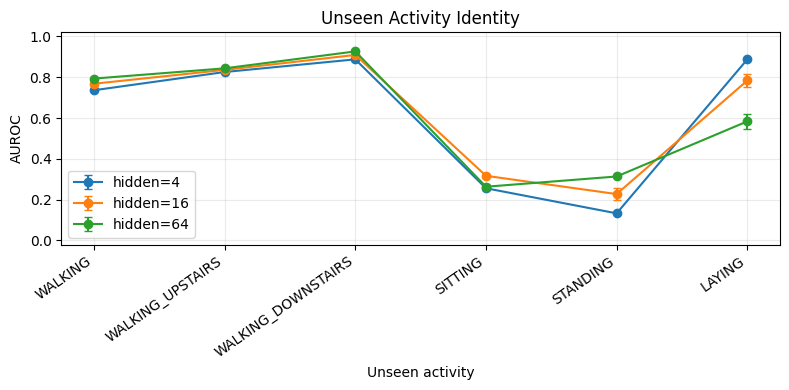

In [29]:
# Plot AUROC as the excluded activity changes
plot_comparison(results_A, "unseen_id", "Unseen Activity Identity",
                "Unseen activity", activity_ticks=True)

### Patch Size

Vary patch size while keeping the same seen activities.

In [30]:
# List patch-size conditions, holding other settings fixed
scenarios_C = PATCH_SIZES

In [31]:
# Train, score, and record each patch-size condition
rows_C = []
data_C = baseline_data
for patch in scenarios_C:
    for hidden, seed in product(HIDDENS, SEEDS):
        model, history = fit_configuration(data_C, BASE_SEEN, hidden, seed, patch=patch)
        seen_scores = reconstruction_scores(model, data_C["seen_test"], patch=patch)
        unseen_scores = reconstruction_scores(model, data_C["unseen_test"][BASE_UNSEEN], patch=patch)
        rows_C.append(result_row(BASE_UNSEEN, hidden, seed, patch, MASK_RATIO,
                                 seen_scores, unseen_scores))
    print(f"patch={patch} Completed")
results_C = pd.DataFrame(rows_C)

patch=4 Completed
patch=8 Completed
patch=16 Completed
patch=32 Completed


In [32]:
# Summarize reconstruction MSE and AUROC by patch size and model capacity
table_C = summarize_results(results_C, ["patch_size", "hidden"])
display(table_C.round(4))

,patch_size,hidden,seen_MSE,unseen_MSE,AUROC_mean,AUROC_std
0,4,4,0.7819,2.1752,0.8924,0.0077
1,4,16,0.6164,1.3598,0.8156,0.0114
2,4,64,0.5099,0.5457,0.5669,0.0201
3,8,4,0.7807,2.1143,0.8876,0.0048
4,8,16,0.6312,1.2849,0.7841,0.0297
5,8,64,0.5382,0.6169,0.5837,0.0368
6,16,4,0.7843,2.0522,0.8779,0.0119
7,16,16,0.6496,1.3659,0.7978,0.0317
8,16,64,0.5642,0.6581,0.5755,0.0136
9,32,4,0.7892,2.0844,0.8779,0.0085


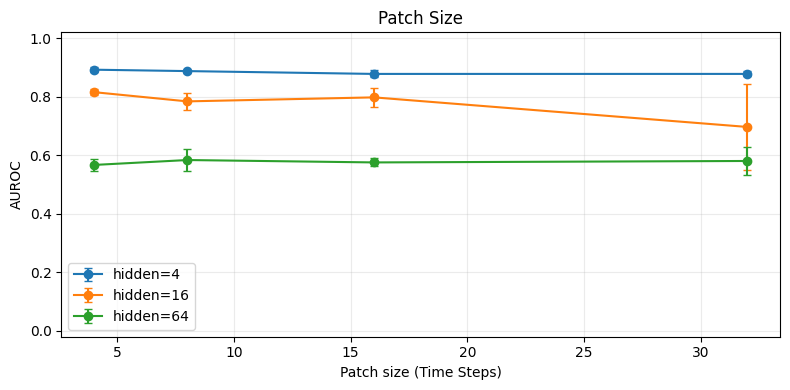

In [33]:
# Plot sensitivity to patch size
plot_comparison(results_C, "patch_size", "Patch Size", "Patch size (Time Steps)")

### Masking Ratio

Vary the masking ratio while keeping the same seen activities.

In [34]:
# List masking-ratio conditions, holding other settings fixed
scenarios_D = MASK_RATIOS

In [35]:
# Train, score, and record each masking-ratio condition
rows_D = []
data_D = baseline_data
for mask_ratio in scenarios_D:
    for hidden, seed in product(HIDDENS, SEEDS):
        model, history = fit_configuration(data_D, BASE_SEEN, hidden, seed,
                                           mask_ratio=mask_ratio)
        seen_scores = reconstruction_scores(model, data_D["seen_test"], mask_ratio=mask_ratio)
        unseen_scores = reconstruction_scores(model, data_D["unseen_test"][BASE_UNSEEN],
                                              mask_ratio=mask_ratio)
        rows_D.append(result_row(BASE_UNSEEN, hidden, seed, PATCH, mask_ratio,
                                 seen_scores, unseen_scores))
    print(f"ratio={mask_ratio} Completed")
results_D = pd.DataFrame(rows_D)

ratio=0.25 Completed
ratio=0.5 Completed
ratio=0.75 Completed


In [36]:
# Summarize reconstruction MSE and AUROC by masking ratio and model capacity
table_D = summarize_results(results_D, ["mask_ratio", "hidden"])
display(table_D.round(4))

,mask_ratio,hidden,seen_MSE,unseen_MSE,AUROC_mean,AUROC_std
0,0.25,4,0.7824,2.0854,0.8784,0.0043
1,0.25,16,0.6302,1.3276,0.7948,0.0061
2,0.25,64,0.5216,0.6898,0.6189,0.0037
3,0.50,4,0.7807,2.1143,0.8876,0.0048
4,0.50,16,0.6312,1.2849,0.7841,0.0297
5,0.50,64,0.5382,0.6169,0.5837,0.0368
6,0.75,4,0.7912,2.0368,0.8672,0.0285
7,0.75,16,0.6607,1.3275,0.7748,0.0553
8,0.75,64,0.5869,0.6229,0.5552,0.0251


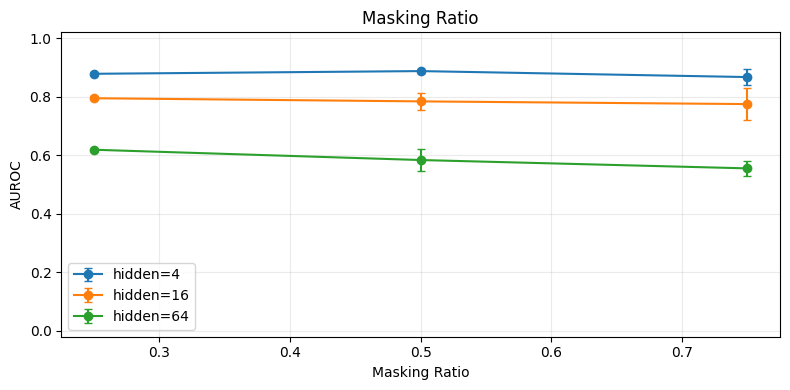

In [37]:
# Plot sensitivity to the masking ratio
plot_comparison(results_D, "mask_ratio", "Masking Ratio", "Masking Ratio")

### Conclusion

The experimental results highlight a trade-off between reconstruction accuracy and out-of-distribution detection performance.

Increasing the hidden dimension from 4 to 64 consistently reduced the training MSE and test reconstruction errors, but also decreased AUROC. This suggests that larger models reconstruct both seen and unseen activities more effectively, reducing their ability to distinguish between them.

The activity-wise analysis further shows that detection performance depends strongly on the unseen activity. Regarding patch size, smaller patches generally provided better detection performance. The masking ratio also influenced performance.

Overall, these findings suggest that a smaller model with relatively small patches and moderate masking is more effective for reconstruction-based OOD detection, even though larger models achieve lower reconstruction errors.